# NLP-Themenanalyse von Beschwerdetexten

Automatische Extraktion der häufigsten Themen aus deutschsprachigen Beschwerden (**GermEval 2017**, Deutsche Bahn) mit Methoden der maschinellen Sprachverarbeitung (NLP).

**Ablauf:** Daten laden → Vorverarbeitung → Vektorisierung (Bag-of-Words & TF-IDF) → Themen-Extraktion (NMF & LDA) → Visualisierung.

Portfolio zum IU-Kurs „Projekt: Data Analysis" (DLBDSEDA02).

## 0. Setup

Installiert die benötigten Pakete und das deutsche spaCy-Sprachmodell (vor allem für Google Colab nötig). Lokal, wo alles schon installiert ist, schadet es nicht.

In [1]:
!pip install pandas scikit-learn spacy matplotlib wordcloud gensim -q
!python -m spacy download de_core_news_sm -q


[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


[+] Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')



[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
import os
import re
import pandas as pd
import spacy
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation
import matplotlib.pyplot as plt
from wordcloud import WordCloud

nlp = spacy.load("de_core_news_sm", disable=["parser", "ner"])

## 1. Daten laden

Datenquelle: **GermEval 2017** – rund 19.400 reale deutschsprachige Beschwerden über die Deutsche Bahn (öffentlicher Dienstleister). Ist eine lokale Kopie (`data/germeval.csv`) vorhanden, wird sie genutzt; sonst wird von Hugging Face geladen. Zur besseren Laufzeit wird eine Stichprobe von 10.000 Dokumenten gezogen.

In [3]:
DATA_URL = "https://huggingface.co/datasets/akash418/germeval_2017/resolve/main/train.csv"
LOCAL_CSV = "data/germeval.csv"

if os.path.exists(LOCAL_CSV):
    df = pd.read_csv(LOCAL_CSV)
    print(f"Lokal geladen: {len(df)} Dokumente")
else:
    df = pd.read_csv(DATA_URL)
    print(f"Von Hugging Face geladen: {len(df)} Dokumente")

df["text"] = df["text"].astype(str).str.strip()
df = df.drop_duplicates(subset="text")
df = df.sample(10000, random_state=24).reset_index(drop=True)
df[["text"]].head()

Lokal geladen: 19432 Dokumente


,text
0,Bahn wehrt sich: „Wand pinkelt zurück“ « Wirts...
1,"@Schlachtzeile das ist der Grund, warum ich ke..."
2,R-Bahn R1 Richtung Plochingen mit der nächsten...
3,Heute morgen in der Bahn eine Frau mit 6 Ringe...
4,Transporter Mieten AHK Ikea Umzug Küche Transp...


## 2. Vorverarbeitung

Die Texte werden gesäubert: Kleinschreibung, Entfernen von URLs und @-Namen (Regex), dann Tokenisierung und Lemmatisierung mit spaCy. Behalten werden nur Grundformen echter Wörter – ohne Stoppwörter und ohne sehr kurze Wörter. `nlp.pipe` verarbeitet die Texte im Batch (schnell).

In [4]:
def clean_regex(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    return text


def lemmas_from_doc(doc):
    words = []
    for t in doc:
        lemma = t.lemma_.lower()
        if t.is_alpha and not t.is_stop and len(lemma) >= 3:
            words.append(lemma)
    return " ".join(words)


cleaned = []
for t in df["text"]:
    cleaned.append(clean_regex(t))

docs = []
for doc in nlp.pipe(cleaned, batch_size=500):
    docs.append(lemmas_from_doc(doc))

print("Beispiel (vorher): ", df["text"].iloc[0])
print("Beispiel (nachher):", docs[0])

Beispiel (vorher):  Bahn wehrt sich: „Wand pinkelt zurück“ « WirtschaftsBlatt.at "Köln . Die Deutsche Bahn schreckt Wildpinkler am Kölner Hauptbahnhof neuerdings mit Schildern ab, auf denen steht: ""Hier nicht pinkeln! Wand pinkelt zurück."" Die Spezialwand sei mit einem besonders feuchtigkeitsabweisenden Lack beschichtet, teilte"
Beispiel (nachher): bahn wehren wand pinkelen köln deutsch bahn schrecken wildpinkler kölner hauptbahnhof neuerdings schilder stehen pinkel wand pinkelen spezialwand feuchtigkeitsabweisend lack beschichten teilen


## 3. Vektorisierung

Die sauberen Texte werden in numerische Vektoren umgewandelt. Zwei Verfahren im Vergleich: **Bag-of-Words** (reine Häufigkeiten) und **TF-IDF** (zusätzlich nach Seltenheit gewichtet). Zusätzlich werden domänenspezifische Rauschwörter entfernt.

In [5]:
EXTRA_STOPWORDS = ["deutsch", "deutsche", "deutschen", "bahn", "db", "mal", "gutefrage", "net", "nen", "hab",
                   "hallo", "einfach", "eigentlich", "umsonst", "letzter", "nächster", "normal", "sogar",
                   "montag", "dienstag", "mittwoch", "donnerstag", "freitag", "samstag", "sonntag", "fast", "via"]

bow_vectorizer = CountVectorizer(min_df=10, max_df=0.5, stop_words=EXTRA_STOPWORDS)
bow_matrix = bow_vectorizer.fit_transform(docs)

tfidf_vectorizer = TfidfVectorizer(min_df=10, max_df=0.5, stop_words=EXTRA_STOPWORDS)
tfidf_matrix = tfidf_vectorizer.fit_transform(docs)

print("Bag-of-Words:", bow_matrix.shape)
print("TF-IDF:      ", tfidf_matrix.shape)

Bag-of-Words: (10000, 1888)
TF-IDF:       (10000, 1888)


## 4. Wahl der Themenzahl (k)

Die Themenzahl wird mit zwei Methoden untersucht: der **Ellbogen-Methode** (NMF-Rekonstruktionsfehler) und dem **Coherence Score (C_v)**. Beide sind rechenintensiv, daher laufen sie auf einer kleineren Stichprobe von 5.000 Dokumenten.

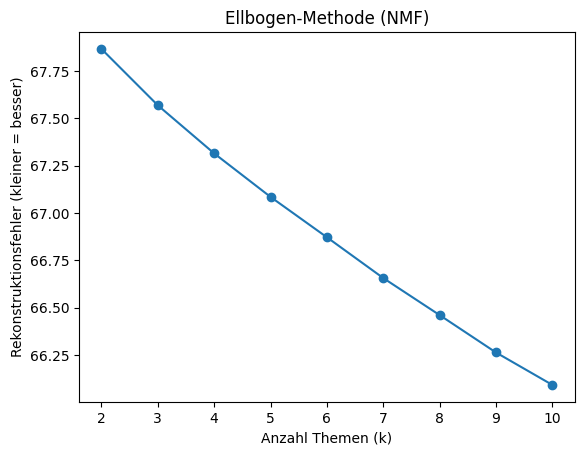

In [6]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

# kleinere Stichprobe fuer die (rechenintensive) Themenzahl-Analyse
docs_sample = docs[:5000]
vec_sample = TfidfVectorizer(min_df=10, max_df=0.5, stop_words=EXTRA_STOPWORDS)
tfidf_sample = vec_sample.fit_transform(docs_sample)

# Ellbogen-Methode: NMF-Rekonstruktionsfehler je Themenzahl
k_values = []
errors = []
for k in range(2, 11):
    model = NMF(n_components=k, init="nndsvda", max_iter=400, random_state=24)
    model.fit(tfidf_sample)
    k_values.append(k)
    errors.append(model.reconstruction_err_)

plt.plot(k_values, errors, marker="o")
plt.xlabel("Anzahl Themen (k)")
plt.ylabel("Rekonstruktionsfehler (kleiner = besser)")
plt.title("Ellbogen-Methode (NMF)")
plt.show()

k=2: Coherence=0.3521


k=3: Coherence=0.5685


k=4: Coherence=0.5234


k=5: Coherence=0.5195


k=6: Coherence=0.5320


k=7: Coherence=0.4816


k=8: Coherence=0.4743


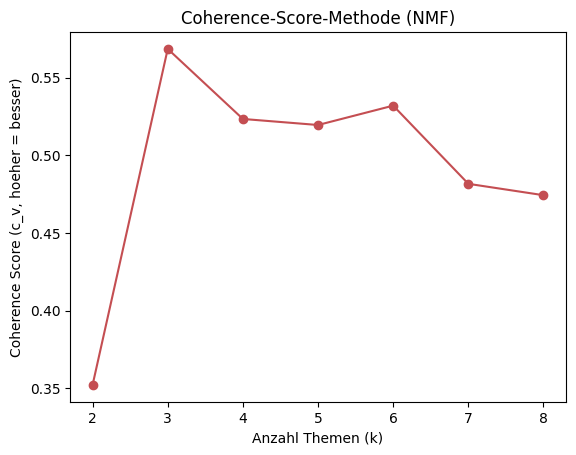

In [7]:
# Coherence Score (C_v) je Themenzahl -- rechenintensiv, dauert einige Minuten
words_sample = vec_sample.get_feature_names_out()

texts_tokens = []
for d in docs_sample:
    texts_tokens.append(d.split())
dictionary = Dictionary(texts_tokens)

k_values = []
scores = []
for k in range(2, 9):
    model = NMF(n_components=k, init="nndsvda", max_iter=400, random_state=24)
    model.fit(tfidf_sample)
    topics = []
    for topic in model.components_:
        top_words = []
        for i in topic.argsort()[::-1][:10]:
            top_words.append(words_sample[i])
        topics.append(top_words)
    cm = CoherenceModel(topics=topics, texts=texts_tokens,
                        dictionary=dictionary, coherence="c_v")
    k_values.append(k)
    scores.append(cm.get_coherence())
    print(f"k={k}: Coherence={scores[-1]:.4f}")

plt.plot(k_values, scores, marker="o", color="#C44E52")
plt.xlabel("Anzahl Themen (k)")
plt.ylabel("Coherence Score (c_v, hoeher = besser)")
plt.title("Coherence-Score-Methode (NMF)")
plt.show()

**Fazit:** Der Ellbogen liefert kein eindeutiges Ergebnis – ein klarer Knick ist nicht erkennbar. Der Coherence Score ist im Bereich k=3–6 hoch und fällt ab k=7 ab; das Maximum bei k=3 spiegelt die Tendenz von C_v wider, *wenige, breite* Themen zu bevorzugen. Da k=3 die unterscheidbaren Beschwerdethemen verschmelzen würde, wird **k = 6** gewählt – im kohärenzstarken Bereich und zugleich klar interpretierbar.

## 5. Themen-Extraktion

Zwei Verfahren werden eingesetzt und verglichen: **NMF** (auf TF-IDF, algebraisch) und **LDA** (auf Bag-of-Words, probabilistisch).

In [8]:
N_TOPICS = 6

nmf_model = NMF(n_components=N_TOPICS, init="nndsvda", max_iter=400, random_state=24)
nmf_model.fit(tfidf_matrix)

lda_model = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch", max_iter=20, random_state=24)
lda_model.fit(bow_matrix)


def show_topics(model, vectorizer, n_words=10):
    words = vectorizer.get_feature_names_out()
    for topic_index, topic in enumerate(model.components_):
        top_indices = topic.argsort()[::-1][:n_words]
        top_words = []
        for i in top_indices:
            top_words.append(words[i])
        print(f"Thema {topic_index + 1}:", ", ".join(top_words))


print("=== NMF (auf TF-IDF) ===")
show_topics(nmf_model, tfidf_vectorizer)
print("\n=== LDA (auf Bag-of-Words) ===")
show_topics(lda_model, bow_vectorizer)

=== NMF (auf TF-IDF) ===
Thema 1: fahren, auto, züge, zug, arbeit, nehmen, schnell, station, selber, hause
Thema 2: verspätung, stehen, minute, ice, sitzen, sehen, ticket, warten, hbf, finden
Thema 3: gdl, beenden, streik, schlichtung, tarifkonflikt, bahnstreik, lokführergewerkschaft, weselsky, lokführer, einigung
Thema 4: bus, auto, deutschland, ticket, kostenlos, mensch, swb, unterwegs, hause, nutzen
Thema 5: berlin, planen, deutlich, berliner, dpa, zahl, erhöhen, verkehrsmeldungen, gut, angabe
Thema 6: zug, versprechen, grube, umgekehrt, wagenreihung, service, digitalisierung, chaos, bahnsteig, ausfallen

=== LDA (auf Bag-of-Words) ===
Thema 1: minute, verspätung, hbf, strecke, münchen, zug, stehen, hamburg, störung, stuttgart
Thema 2: ticket, deutschland, berlin, finden, starten, reise, kind, flüchtling, alt, klasse
Thema 3: bus, fahren, auto, mensch, sehen, sitzen, leben, voll, frau, leute
Thema 4: fahren, zug, stehen, hannover, bekommen, ice, warten, wissen, nehmen, pünktlich
The

## 6. Visualisierung

Wortwolken je Thema – die Wortgröße entspricht der Wichtigkeit des Wortes für das Thema.

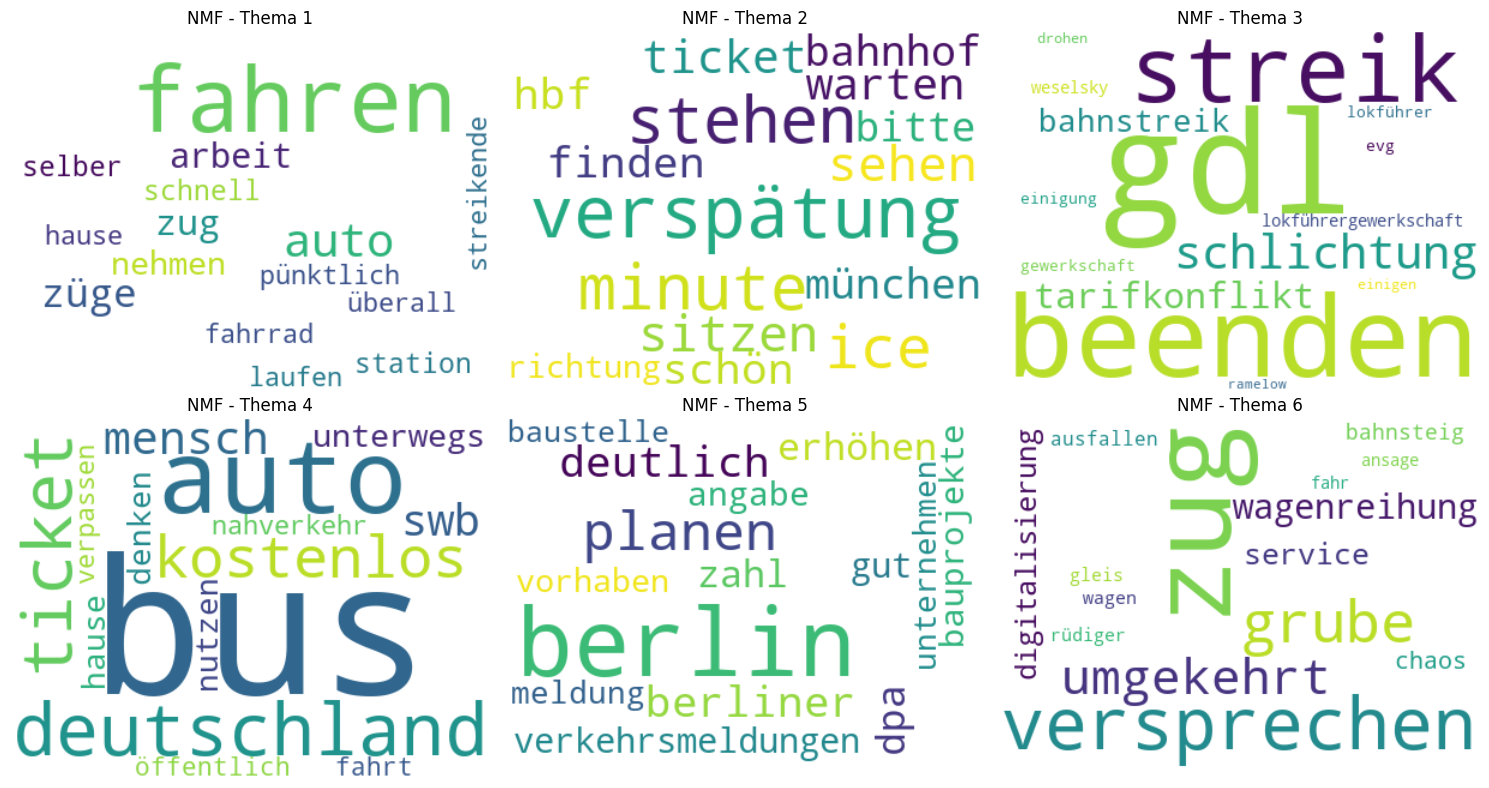

In [9]:
def show_wordclouds(model, vectorizer, method, n_words=15):
    words = vectorizer.get_feature_names_out()
    n_topics = len(model.components_)
    cols = 3
    rows = (n_topics + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
    axes = axes.ravel()
    for i, topic in enumerate(model.components_):
        top_indices = topic.argsort()[::-1][:n_words]
        weights = {}
        for idx in top_indices:
            weights[words[idx]] = topic[idx]
        cloud = WordCloud(width=400, height=300, background_color="white",
                          colormap="viridis").generate_from_frequencies(weights)
        axes[i].imshow(cloud, interpolation="bilinear")
        axes[i].set_title(f"{method} - Thema {i + 1}")
        axes[i].axis("off")
    for j in range(n_topics, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()


show_wordclouds(nmf_model, tfidf_vectorizer, "NMF")

## 7. Diskussion & Fazit

- **NMF** liefert für diese Daten trennschärfere, besser interpretierbare Themen als **LDA** (die LDA-Themen überlappen stärker).
- Identifizierte Kernthemen: **Verspätung/Warten**, **Streik/Tarifkonflikt**, **Bus/Nahverkehr**, **Strecken & Meldungen**, **Service/Management** sowie ein allgemeines Fahrt-Thema.
- Die Themenzahl **k = 6** wurde über Ellbogen-Methode und Coherence Score begründet.
- **Grenzen:** Das kleine spaCy-Modell lemmatisiert nicht immer perfekt; einzelne Rauschwörter bleiben; nicht alle Texte sind echte Beschwerden.